# 01 - Exploration des données

Questions explorées :
1. Qui sont les chiens (profils) ?
2. Quels comportements, avec quelles fréquences ?
3. Les comportements de `Behavior_1`, `Behavior_2`, `Behavior_3` sont-ils exclusifs ? (→ justifie les
   modèles spécifiques par famille)
4. À quoi ressemblent les signaux ?

In [1]:
import sys
from pathlib import Path

# Racine du projet ajoutée au chemin d'import (le notebook est dans notebooks/)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config as cfg
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

from src import data, labels, viz

In [2]:
moves = data.load_moves()
dogs = data.load_dogs()

## 1. Profils des chiens

,renseignées,manquantes,valeurs uniques,type
DogID,45,0,45,int64
Breed,45,0,26,str
Weight,45,0,21,int64
Age months,45,0,38,int64
Gender,45,0,2,int64
NeuteringStatus,45,0,2,int64
Classe_Poids,45,0,3,category
Classe_Age,45,0,3,category


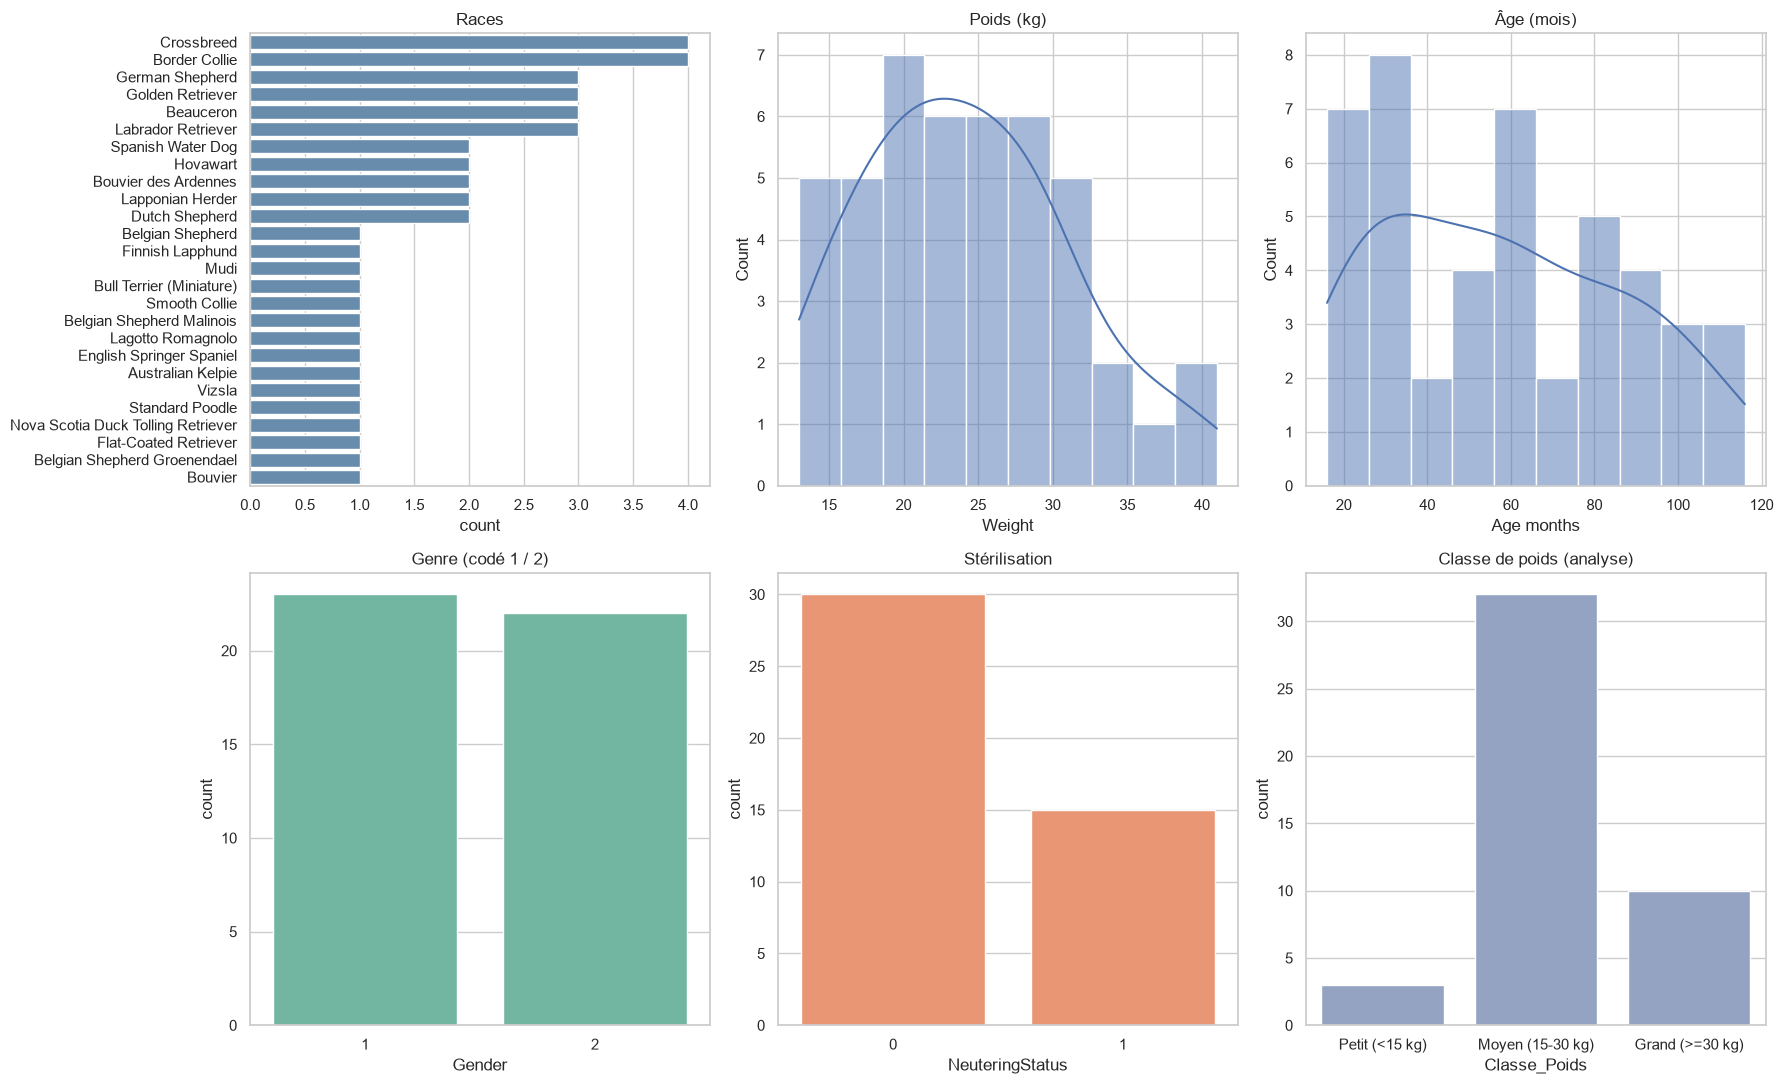

In [3]:
def resume_colonnes(df):
    return pd.DataFrame({"renseignées": df.count(), "manquantes": df.isna().sum(),
                         "valeurs uniques": df.nunique(), "type": df.dtypes.astype(str)})

display(resume_colonnes(dogs))

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()
sns.countplot(data=dogs, y="Breed", order=dogs["Breed"].value_counts().index, ax=axes[0], color="#5b8db8")
axes[0].set_title("Races"); axes[0].set_ylabel("")
sns.histplot(data=dogs, x="Weight", bins=10, kde=True, ax=axes[1]); axes[1].set_title("Poids (kg)")
sns.histplot(data=dogs, x="Age months", bins=10, kde=True, ax=axes[2]); axes[2].set_title("Âge (mois)")
sns.countplot(data=dogs, x="Gender", ax=axes[3], color="#66c2a5"); axes[3].set_title("Genre (codé 1 / 2)")
sns.countplot(data=dogs, x="NeuteringStatus", ax=axes[4], color="#fc8d62"); axes[4].set_title("Stérilisation")
sns.countplot(data=dogs, x="Classe_Poids", ax=axes[5], color="#8da0cb"); axes[5].set_title("Classe de poids (analyse)")
plt.tight_layout(); viz.savefig(fig, "01_profils_chiens"); plt.show()

**À retenir** : 26 races pour 45 chiens → la race n'est pas exploitable comme variable (trop de modalités,
presque une par chien). Les variables de profil (poids, âge...) ne prennent qu'**une valeur par chien** :
avec ~36 chiens d'apprentissage, un modèle peut s'en servir pour « reconnaître le chien » plutôt que pour
généraliser. On testera leur apport (notebook 04) sans en attendre beaucoup.

## 2. Fréquence des comportements

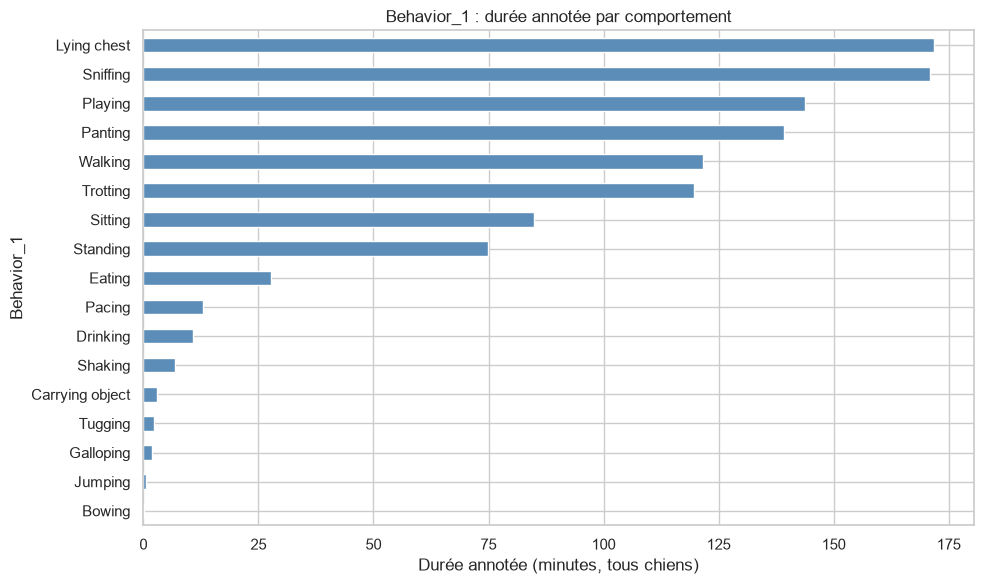

Nombre de chiens présentant chaque comportement :
Behavior_1
Lying chest        45
Standing           45
Sniffing           45
Shaking            45
Walking            45
Playing            45
Trotting           44
Panting            44
Eating             41
Sitting            39
Drinking           35
Pacing             32
Carrying object    20
Galloping          15
Jumping             9
Tugging             8
Bowing              2


In [4]:
minutes = (moves["Behavior_1"].value_counts() / cfg.SAMPLING_RATE / 60).round(1)
fig, ax = plt.subplots(figsize=(10, 6))
minutes.sort_values().plot.barh(ax=ax, color="#5b8db8")
ax.set_xlabel("Durée annotée (minutes, tous chiens)")
ax.set_title("Behavior_1 : durée annotée par comportement")
plt.tight_layout(); viz.savefig(fig, "01_durees_behavior1"); plt.show()
print("Nombre de chiens présentant chaque comportement :")
print(moves.dropna(subset=["Behavior_1"]).groupby("Behavior_1", observed=True)["DogID"].nunique()
      .sort_values(ascending=False).to_string())

Les classes sont **très déséquilibrées** (de quelques secondes à plusieurs heures) et certaines n'existent que
chez quelques chiens. Conséquences pour la suite :
- métrique principale : **F1 macro** (chaque classe compte autant) plutôt que l'exactitude ;
- classes trop rares (< 500 fenêtres dans le train) exclues de la tâche, en le signalant (notebook 04).

## 3. Couverture des annotations par séance

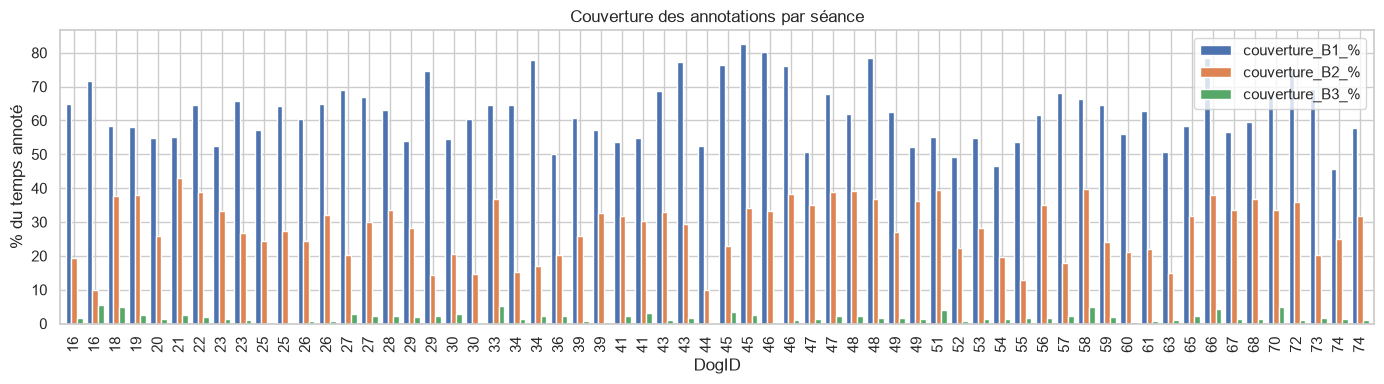

In [5]:
coverage = data.label_coverage(moves)
fig, ax = plt.subplots(figsize=(14, 4))
coverage.plot.bar(x="DogID", y=["couverture_B1_%", "couverture_B2_%", "couverture_B3_%"], ax=ax, width=0.8)
ax.set_ylabel("% du temps annoté"); ax.set_title("Couverture des annotations par séance")
plt.tight_layout(); plt.show()

## 4. Les comportements sont-ils exclusifs ?

On croise `Behavior_1` et `Behavior_2` (durée en lignes où les deux sont annotés simultanément).

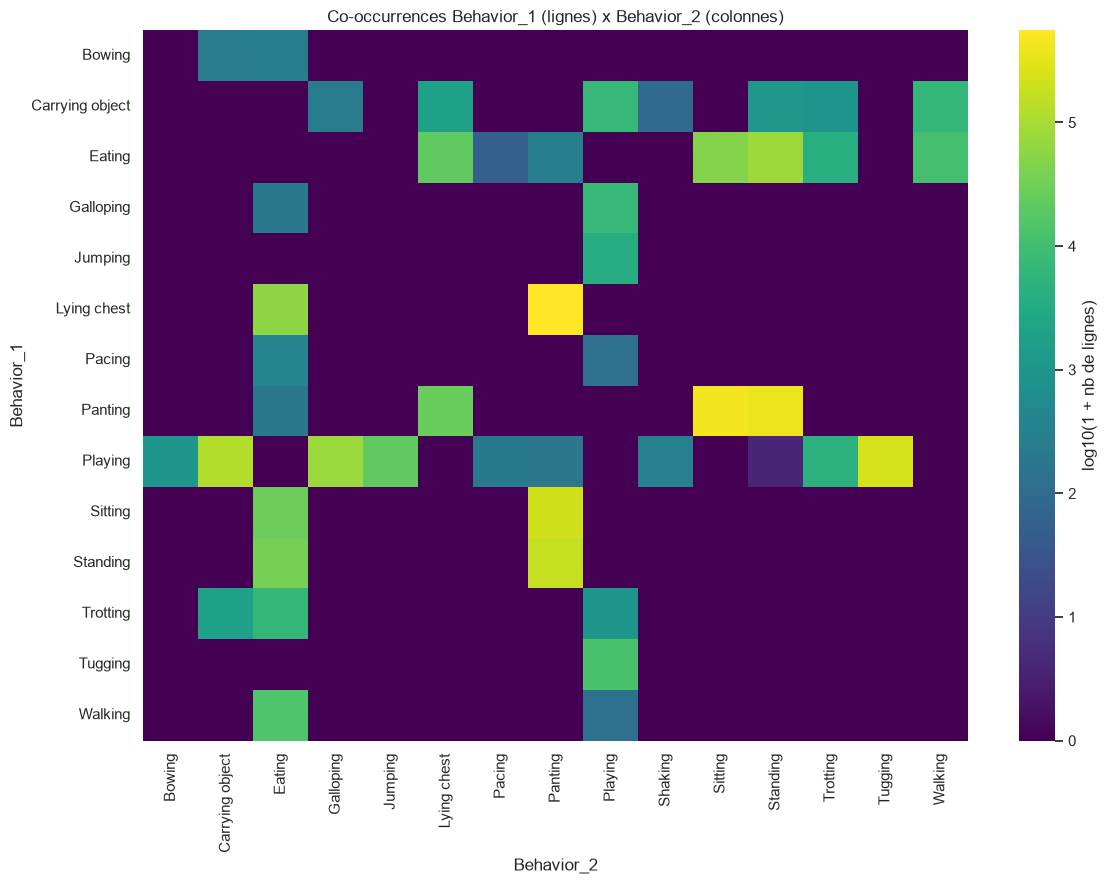

In [6]:
co = labels.cooccurrence(moves, "Behavior_1", "Behavior_2")
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(np.log10(co + 1), cmap="viridis", ax=ax, cbar_kws={"label": "log10(1 + nb de lignes)"})
ax.set_title("Co-occurrences Behavior_1 (lignes) x Behavior_2 (colonnes)")
plt.tight_layout(); viz.savefig(fig, "01_cooccurrences"); plt.show()

**Constat** : `Behavior_1` mélange des **postures** (couché, assis, debout), de la **locomotion** (marche,
trot, galop...) et des **activités** (renifler, manger, haleter...). Ces catégories ne sont pas exclusives :
un chien peut haleter en étant debout. Une partie des confusions d'un modèle « général » est donc
**structurelle** et pas due au modèle.

**Parti pris** : en plus du modèle général, on entraîne des modèles **spécifiques par famille** dont les
classes, elles, s'excluent mutuellement. Le label d'une famille est cherché dans `Behavior_1`, `2` ou `3`.

In [7]:
for fam, labs in cfg.FAMILIES.items():
    mask = np.zeros(len(moves), dtype=bool)
    for col in cfg.BEHAVIOR_COLUMNS:
        mask |= moves[col].isin(labs).to_numpy()
    print(f"{fam:<11} : {mask.mean():6.1%} du temps porte un label de la famille -> {labs}")

posture     :  30.9% du temps porte un label de la famille -> ['Lying chest', 'Sitting', 'Standing']
locomotion  :  17.5% du temps porte un label de la famille -> ['Walking', 'Trotting', 'Pacing', 'Galloping', 'Jumping']
activite    :  39.3% du temps porte un label de la famille -> ['Sniffing', 'Eating', 'Drinking', 'Playing', 'Panting', 'Shaking', 'Carrying object', 'Tugging', 'Bowing']


## 5. La colonne `Task`

`Task` décrit l'exercice du protocole expérimental (ex. « marcher en laisse »). Elle est très liée au
comportement mais **ne serait pas disponible en usage réel** : on ne l'utilise jamais comme variable
d'entrée (ce serait une forme de fuite d'information).

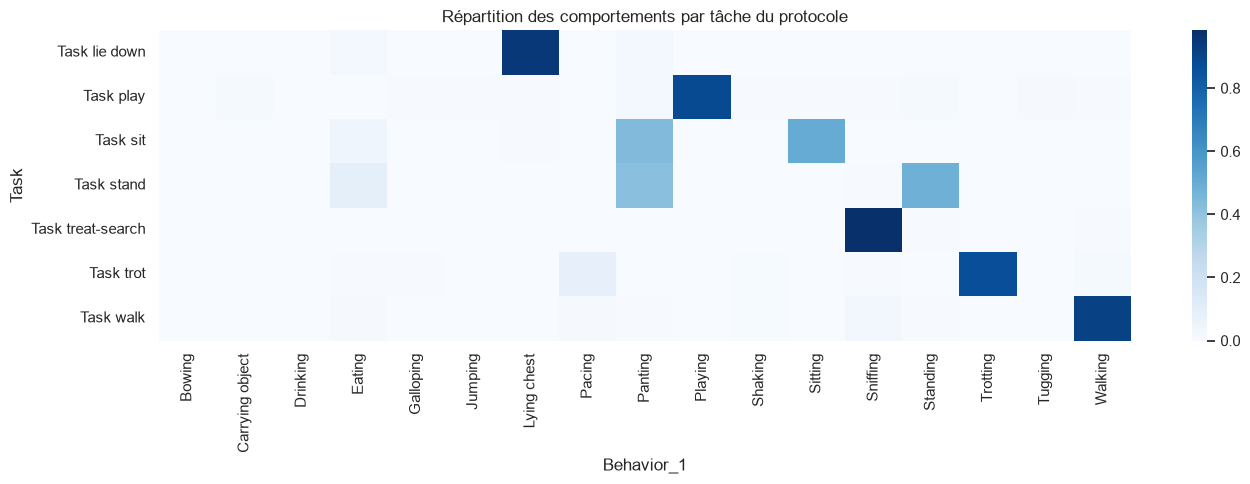

In [8]:
ct = pd.crosstab(moves["Task"].astype(str), moves["Behavior_1"].astype(str), normalize="index")
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(ct, cmap="Blues", ax=ax)
ax.set_title("Répartition des comportements par tâche du protocole")
plt.tight_layout(); plt.show()

## 6. Visualisation interactive des signaux

Le comportement annoté est superposé aux signaux. La moyenne des axes d'accélération change avec la
posture (orientation de la gravité) ; l'amplitude et la périodicité changent avec la locomotion.

In [9]:
from ipywidgets import interact, Dropdown

sessions = moves[cfg.SESSION_KEYS].drop_duplicates().sort_values(cfg.SESSION_KEYS)
options = {f"Chien {d} - test {t}": (int(d), int(t)) for d, t in sessions.itertuples(index=False)}

def afficher(seance, capteur, comportement):
    fig = viz.plot_session_signals(moves, dogs, *seance, sensor=capteur, behavior_col=comportement)
    if fig is not None:
        plt.show()

interact(afficher,
         seance=Dropdown(options=options, description="Séance"),
         capteur=Dropdown(options=cfg.SENSORS, description="Capteur"),
         comportement=Dropdown(options=cfg.BEHAVIOR_COLUMNS, description="Label"));

interactive(children=(Dropdown(description='Séance', options={'Chien 16 - test 1': (16, 1), 'Chien 16 - test 2…